<a href="https://colab.research.google.com/github/saravaneswaran-coder/Linear-Regression-from-scratch-in-numpy/blob/main/Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

iteration 0 : cost 1.3487
iteration 1000 : cost 0.3281
iteration 2000 : cost 0.2908
iteration 3000 : cost 0.2823
iteration 4000 : cost 0.2781
iteration 5000 : cost 0.2754
iteration 6000 : cost 0.2736
iteration 7000 : cost 0.2723
iteration 8000 : cost 0.2715
iteration 9000 : cost 0.2709
iteration 10000 : cost 0.2704


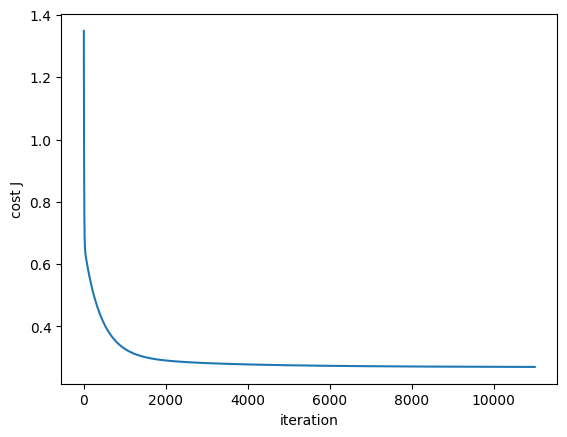

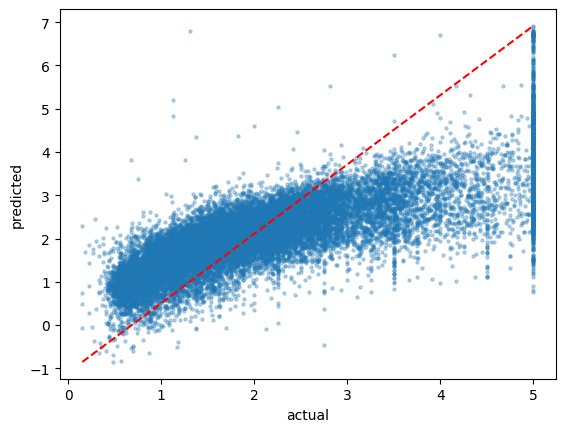

In [28]:
#Importing the Dataset
from sklearn.datasets import fetch_california_housing
import numpy as np
data = fetch_california_housing(as_frame=True)
df = data.frame

#Getting X and Y
X = df.drop(columns=["MedHouseVal"]).to_numpy() #20640,8
y = df["MedHouseVal"].to_numpy()                #20648,

#Feature Scaling: using mean normalization this uses numpy broadcasting
mue = X.mean(axis = 0)                     #mue shape(,8)
deno = X.max(axis=0) - X.min(axis=0)       #deno shape is (,8)
X_norm = (X - mue)/deno                    #by broadcasting mue and deno applies to entire X(26480,8)


#List of all initial initializations
w = np.array([0.001,0.002,0.003,0.004,0.005,0.006,0.007,0.008])  #w.shape = (8,)
b = 0.9
a = 0.07
iterations = 11000
cost_history = []

for iter in range(iterations):

  #constructing the line(prediction)
  y_hat = np.dot(X_norm,w) + b       #dot (26480,8)*(8,) = (26480,)
  error = y_hat - y

  #constructing the cost function
  m = X_norm.shape[0]
  j = np.sum((error)**2)             #sums up all diff between y_hat and y
  j = (1/(2*m))*j
  cost_history.append(j)

  #Calculating Gradients
  dj_dw = np.dot(X_norm.T,error)*(1/m)    #dot(8,26480)*(26480,) = (8,)
  dj_db = np.sum(error)/m                 #sum of all err divided by m

  #Applying Gradient Descent
  w = w - a*dj_dw
  b = b - a*dj_db

  #Displaying iteration and cost
  if iter%1000 == 0:
    print(f"iteration {iter} : cost {j:.4f}")

import matplotlib.pyplot as plt
plt.plot(cost_history)
plt.xlabel("iteration"); plt.ylabel("cost J")
plt.show()


plt.scatter(y, y_hat, alpha=0.3, s=5)
plt.plot([y.min(), y.max()], [y_hat.min(), y_hat.max()], "r--")
plt.xlabel("actual"); plt.ylabel("predicted")
plt.show()


